### Downloading dataset from kaggle

In [2]:
import kagglehub
path = kagglehub.dataset_download("liuxu77/largest")

print("Path to dataset files:", path)

100%|██████████| 7.04G/7.04G [01:31<00:00, 82.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/liuxu77/largest/versions/1


In [4]:
import os
print("Root contents:", os.listdir(path))
for root, dirs, files in os.walk(path):
    if files:
        print(f"\nFolder: {root}")
        print("Files (first 10):", files[:10])


Root contents: ['ca_his_raw_2019.h5', 'ca_his_raw_2017.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_his_raw_2018.h5', 'ca_rn_adj.npy', 'ca_his_raw_2020.h5']

Folder: /root/.cache/kagglehub/datasets/liuxu77/largest/versions/1
Files (first 10): ['ca_his_raw_2019.h5', 'ca_his_raw_2017.h5', 'ca_his_raw_2021.h5', 'ca_meta.csv', 'ca_his_raw_2018.h5', 'ca_rn_adj.npy', 'ca_his_raw_2020.h5']


### About data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    DATA_DIR = path
except NameError:
    DATA_DIR = "/root/.cache/kagglehub/datasets/liuxu77/largest/versions/1"

# this sensor's meta data e.g
META_FILE = "ca_meta.csv"
# road network like road-distance adjacency for all of california
ADJ_FILE = "ca_rn_adj.npy"
# frequency of 5 minute flow
RAW_FILES = ["ca_his_raw_2020.h5", "ca_his_raw_2021.h5"]
OUT_DIR = "outputs"

# san diego subset size
EXPECTED_NODES = 716
# "sum" = vehicles per 15 min, "mean" = average 5-min count
AGGREGATION = "sum"
# Set to True to prevent Colab from running out of RAM (Session Crashes)
LOW_MEMORY = True

WEEK_START = "2020-01-06"
WEEK_END = "2020-01-12"

os.makedirs(OUT_DIR, exist_ok=True)

In [2]:

report_lines = []

def log(text=""):
    print(text)
    report_lines.append(str(text))

def load_year_simple(path, sd_ids):
    # reading the whole California table and then keepin the San Diego columns.
    # This needs a lot of memory because California has 8,600 sensors.
    df = pd.read_hdf(path)
    df.columns = df.columns.astype(str)
    df = df[sd_ids]
    return df.astype(np.float32)


def load_year_low_memory(path, sd_ids):
    # readin the file in small blocks of rows and keeps only San Diego columns.
    # works for h5 files that pandas saved in its default "fixed" format.
    import h5py
    f = h5py.File(path, "r")
    key = list(f.keys())[0]
    group = f[key]
    if "block0_values" not in group:
        f.close()
        raise RuntimeError("Unexpected h5 layout. Set LOW_MEMORY = False.")

    # block0_items holds the column names in the same order as block0_values.
    all_ids = [str(c.decode() if isinstance(c, bytes) else c) for c in group["block0_items"][:]]

    # time index is stored as integers. Older pandas files use nanoseconds.
    kind = group["axis1"].attrs.get("kind", b"datetime64")
    if isinstance(kind, bytes):
        kind = kind.decode()
    time_unit = "ns"
    if "[" in kind:
        time_unit = kind[kind.find("[") + 1:kind.find("]")]
    times = pd.to_datetime(group["axis1"][:], unit=time_unit)
    position_of = {sensor_id: k for k, sensor_id in enumerate(all_ids)}
    cols = np.array([position_of[s] for s in sd_ids])

    values = group["block0_values"]
    n_rows = values.shape[0]
    parts = []
    step = 2000
    for start in range(0, n_rows, step):
        block = values[start:start + step, :]      # a few rows, all sensors
        parts.append(block[:, cols].astype(np.float32))
    f.close()

    data = np.concatenate(parts, axis=0)
    return pd.DataFrame(data, index=times, columns=sd_ids)

### (a) getting data and its sampling

In [3]:
log("=" * 60)
log("a) daata extraction and resampling")
log("=" * 60)

# from metadata taking San Diego sensors by querying county on san diago
meta = pd.read_csv(os.path.join(DATA_DIR, META_FILE))
log("Metadata columns: " + ", ".join(meta.columns))
log("Sensors in California: " + str(len(meta)))

is_sd = (meta["County"] == "San Diego").values
sd_positions = np.where(is_sd)[0]            # row numbers inside the California files
sd_meta = meta[is_sd].reset_index(drop=True)
sd_ids = sd_meta["ID"].astype(str).tolist()  # sensor IDs, in metadata order
N = len(sd_ids)
log("Sensors in San Diego county: " + str(N))

if N != EXPECTED_NODES:
    log("WARNING: expected " + str(EXPECTED_NODES) + " sensors but found " + str(N))
    log("Sensors with District == 11: " + str(int((meta["District"] == 11).sum())))
    log("County names in the file:")
    log(meta["County"].value_counts().to_string())
    raise SystemExit("Stop: the San Diego filter did not give the expected count.")

# loading 1 year data from 2020 to 2021
yearly = []
for name in RAW_FILES:
    path_to_file = os.path.join(DATA_DIR, name)
    print("Reading", path_to_file, "...")
    if LOW_MEMORY:
        df_year = load_year_low_memory(path_to_file, sd_ids)
    else:
        df_year = load_year_simple(path_to_file, sd_ids)
    log(name + " shape (time, sensors): " + str(df_year.shape))
    yearly.append(df_year)

flow5 = pd.concat(yearly, axis=0)
flow5 = flow5.sort_index()
flow5 = flow5.loc["2020-01-01":"2021-12-31"]

# checking if every 5 minute timestamp exists.and assigning missing row as NaN.
full_index_5 = pd.date_range("2020-01-01 00:00", "2021-12-31 23:55", freq="5min")
missing_rows = len(full_index_5) - len(flow5.index.intersection(full_index_5))
flow5 = flow5.reindex(full_index_5)
log("5-minute timestamps expected: " + str(len(full_index_5)))
log("5-minute timestamps missing from the files: " + str(missing_rows))

raw_missing = int(flow5.isna().sum().sum())
raw_total = flow5.shape[0] * flow5.shape[1]
log("Missing 5-minute values: " + str(raw_missing) + " of " + str(raw_total)
    + " (" + str(round(100 * raw_missing / raw_total, 3)) + "%)")

# resample from 5 minutes to 15 minutes
#  mean ignores missing values inside a 15 minute bin.
mean15 = flow5.resample("15min").mean()
if AGGREGATION == "sum":
    # 3 x mean equal the sum when all three readings exist.
    # It also stayed on the correct scale when one reading is missing.
    flow15 = mean15 * 3
    units = "vehicles per 15 minutes"
else:
    flow15 = mean15
    units = "vehicles per 5 minutes (15-minute average)"
del flow5, mean15

T = flow15.shape[0]
log("Aggregation used: " + AGGREGATION + "  -> units: " + units)
log("15-minute data shape (T, N): " + str(flow15.shape))
log("First timestamp: " + str(flow15.index[0]))
log("Last timestamp:  " + str(flow15.index[-1]))

# handling missing values
observed = flow15.notna().values
n_missing = int((~observed).sum())
log("Missing 15-minute values: " + str(n_missing) + " of " + str(T * N)
    + " (" + str(round(100 * n_missing / (T * N), 3)) + "%)")

missing_per_sensor = 100 * (~observed).mean(axis=0)
log("Sensors with no missing values: " + str(int((missing_per_sensor == 0).sum())))
log("Sensors with more than 10% missing: " + str(int((missing_per_sensor > 10).sum())))
log("Sensors with more than 50% missing: " + str(int((missing_per_sensor > 50).sum())))
log("Worst sensor missing percentage: " + str(round(float(missing_per_sensor.max()), 2)) + "%")
log("Exact zero readings (before filling): " + str(int((flow15.values == 0).sum())))

#  copy the last known value forward, then fill the start backward.
# A sensor with no data at all is filled with 0.
flow15 = flow15.ffill().bfill().fillna(0.0)
log("Missing values after filling: " + str(int(flow15.isna().sum().sum())))
log("Flow statistics after filling: min=" + str(round(float(flow15.values.min()), 2))
    + ", mean=" + str(round(float(flow15.values.mean()), 2))
    + ", max=" + str(round(float(flow15.values.max()), 2)))

#ploting three sensors over one week
chosen_three = [0, N // 2, N - 1]
week = flow15.loc[WEEK_START:WEEK_END]               # 7 days x 96 steps = 672 rows

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, k in zip(axes, chosen_three):
    row = sd_meta.iloc[k]
    ax.plot(week.index, week.iloc[:, k], linewidth=1.5)
    ax.set_title("Sensor " + str(row["ID"]) + "  (" + str(row["Fwy"]) + " "
                 + str(row["Direction"]) + ")", fontsize=10, loc="left")
    ax.set_ylabel("Flow")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Time")
fig.suptitle("Traffic flow for three San Diego sensors, " + WEEK_START
             + " to " + WEEK_END + " (" + units + ")")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "q3a_three_sensors_week.png"), dpi=150)
plt.close(fig)
log("rows in the plotted week: " + str(len(week)))
log("sensors plotted: " + ", ".join(sd_ids[k] for k in chosen_three))
log("Saved q3a_three_sensors_week.png")


a) daata extraction and resampling
Metadata columns: ID, Lat, Lng, District, County, Fwy, Lanes, Type, Direction, ID2
Sensors in California: 8600
Sensors in San Diego county: 716
Reading /root/.cache/kagglehub/datasets/liuxu77/largest/versions/1/ca_his_raw_2020.h5 ...
ca_his_raw_2020.h5 shape (time, sensors): (105408, 716)
Reading /root/.cache/kagglehub/datasets/liuxu77/largest/versions/1/ca_his_raw_2021.h5 ...
ca_his_raw_2021.h5 shape (time, sensors): (105120, 716)
5-minute timestamps expected: 210528
5-minute timestamps missing from the files: 0
Missing 5-minute values: 7636666 of 150738048 (5.066%)
Aggregation used: sum  -> units: vehicles per 15 minutes
15-minute data shape (T, N): (70176, 716)
First timestamp: 2020-01-01 00:00:00
Last timestamp:  2021-12-31 23:45:00
Missing 15-minute values: 2542017 of 50246016 (5.059%)
Sensors with no missing values: 0
Sensors with more than 10% missing: 45
Sensors with more than 50% missing: 43
Worst sensor missing percentage: 100.0%
Exact zero 

### (b) creating the traffic graph

In [5]:
log()
log("=" * 60)
log("Q3(b) Traffic graph")
log("=" * 60)

A_ca = np.load(os.path.join(DATA_DIR, ADJ_FILE))
log("california adjacency shape: " + str(A_ca.shape))
if A_ca.shape[0] != len(meta):
    raise SystemExit("Stop: adjacency size does not match the metadata rows.")

# row k of the adjacency belongs to row k of the metadata.
# I take the same San Diego positions for rows and for columns.
A = A_ca[sd_positions][:, sd_positions].astype(np.float32)
del A_ca

# order verifiction. flow columns and adjacency rows must be the same sensors.
same_order = list(flow15.columns) == sd_ids
log("Flow columns and adjacency rows use the same sensor order: " + str(same_order))
if not same_order:
    raise SystemExit("Stop: sensor order mismatch.")

# nodes and nonzero edges
nonzero = A != 0
diag_nonzero = int(np.diag(nonzero).sum())
total_nonzero = int(nonzero.sum())
log("Number of nodes: " + str(A.shape[0]))
log("Nonzero entries (including diagonal): " + str(total_nonzero))
log("Nonzero diagonal entries (self-loops): " + str(diag_nonzero))
log("Nonzero edges without self-loops: " + str(total_nonzero - diag_nonzero))
log("Density: " + str(round(total_nonzero / (N * N), 5)))
log("Edge weight range: min nonzero=" + str(round(float(A[nonzero].min()), 4))
    + ", max=" + str(round(float(A.max()), 4)))
log("Negative entries: " + str(int((A < 0).sum())))

# checking if graph is symmetric
weights_symmetric = bool(np.allclose(A, A.T, atol=1e-6))
pattern_symmetric = bool(np.array_equal(nonzero, nonzero.T))
one_way = int((nonzero & ~nonzero.T).sum())
log("Weights symmetric (A == A.T): " + str(weights_symmetric))
log("Nonzero pattern symmetric: " + str(pattern_symmetric))
log("Edges that exist in one direction only: " + str(one_way))
log("Largest |A_ij - A_ji|: " + str(round(float(np.abs(A - A.T).max()), 4)))

# heatmap
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(A, cmap="Blues", vmin=0.0, vmax=float(A.max()), interpolation="nearest")
ax.set_title("San Diego road-distance adjacency matrix (" + str(N) + " x " + str(N) + ")")
ax.set_xlabel("Sensor index j")
ax.set_ylabel("Sensor index i")
fig.colorbar(im, ax=ax, label="Edge weight A_ij")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "q3b_adjacency_heatmap.png"), dpi=150)
plt.close(fig)
log("Saved q3b_adjacency_heatmap.png")

# number of neighbours of each sensor
no_self = nonzero.copy()
np.fill_diagonal(no_self, False)
neighbours_out = no_self.sum(axis=1)
neighbours_in = no_self.sum(axis=0)
log("Neighbours per sensor (row count): min=" + str(int(neighbours_out.min()))
    + ", median=" + str(float(np.median(neighbours_out)))
    + ", mean=" + str(round(float(neighbours_out.mean()), 2))
    + ", max=" + str(int(neighbours_out.max())))
log("Neighbours per sensor (column count): min=" + str(int(neighbours_in.min()))
    + ", mean=" + str(round(float(neighbours_in.mean()), 2))
    + ", max=" + str(int(neighbours_in.max())))
log("Sensors with zero neighbours: " + str(int((neighbours_out == 0).sum())))

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(0, neighbours_out.max() + 2) - 0.5
ax.hist(neighbours_out, bins=bins, edgecolor="white")
ax.set_title("Distribution of the number of neighbours per sensor")
ax.set_xlabel("Number of neighbours (nonzero entries in a row, self-loop excluded)")
ax.set_ylabel("Number of sensors")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "q3b_neighbour_distribution.png"), dpi=150)
plt.close(fig)
log("Saved q3b_neighbour_distribution.png")



Q3(b) Traffic graph
california adjacency shape: (8600, 8600)
Flow columns and adjacency rows use the same sensor order: True
Number of nodes: 716
Nonzero entries (including diagonal): 18035
Nonzero diagonal entries (self-loops): 716
Nonzero edges without self-loops: 17319
Density: 0.03518
Edge weight range: min nonzero=0.01, max=1.0
Negative entries: 0
Weights symmetric (A == A.T): False
Nonzero pattern symmetric: False
Edges that exist in one direction only: 3711
Largest |A_ij - A_ji|: 1.0
Saved q3b_adjacency_heatmap.png
Neighbours per sensor (row count): min=0, median=20.0, mean=24.19, max=70
Neighbours per sensor (column count): min=0, mean=24.19, max=68
Sensors with zero neighbours: 8
Saved q3b_neighbour_distribution.png


### (c) defining graph neighbourhood

In [7]:
# (c) graph neighbourhoods
log()
log("=" * 60)
log("Q3(c) One-hop and two-hop neighbourhoods")
log("=" * 60)

# I am picking the sensor with the median number of neighbours, so it is a typical one.
chosen = int(np.argsort(neighbours_out)[N // 2])
row = sd_meta.iloc[chosen]
log("Chosen sensor index: " + str(chosen))
log("Chosen sensor ID: " + str(row["ID"]) + ", freeway " + str(row["Fwy"]) + " "
    + str(row["Direction"]) + ", lanes " + str(row["Lanes"])
    + ", lat " + str(row["Lat"]) + ", lng " + str(row["Lng"]))

one_hop = np.where(no_self[chosen])[0]

# two hop: nodes reached with a path of at most two edges.
steps = no_self.astype(np.int32)
two_step_paths = steps @ steps                       # counts paths of exactly two edges
within_two = no_self[chosen] | (two_step_paths[chosen] > 0)
within_two[chosen] = False                           # do not count the sensor itself
two_hop = np.where(within_two)[0]
only_second = np.setdiff1d(two_hop, one_hop)

log("One-hop neighbours: " + str(len(one_hop)))
log("Two-hop neighbours (at most two edges): " + str(len(two_hop)))
log("Sensors reached only at the second hop: " + str(len(only_second)))
log("One-hop neighbour IDs: " + ", ".join(sd_ids[k] for k in one_hop))
log("First 20 second-hop-only IDs: " + ", ".join(sd_ids[k] for k in only_second[:20]))
log("Freeways among one-hop neighbours: "
    + ", ".join(sorted(set(sd_meta.iloc[one_hop]["Fwy"].astype(str)))))
log("Freeways among two-hop neighbours: "
    + ", ".join(sorted(set(sd_meta.iloc[two_hop]["Fwy"].astype(str)))))

# saving for 4 to 6
np.savez_compressed(
    os.path.join(OUT_DIR, "sd_dataset.npz"),
    flow=flow15.values.astype(np.float32),          # shape (T, N)
    observed=observed,                              # True where the value was not filled
    timestamps=flow15.index.strftime("%Y-%m-%d %H:%M").values,
    adj=A,                                          # shape (N, N)
    sensor_ids=np.array(sd_ids),
)
sd_meta.to_csv(os.path.join(OUT_DIR, "sd_meta.csv"), index=False)
log()
log("Saved sd_dataset.npz and sd_meta.csv")

with open(os.path.join(OUT_DIR, "q3_results.txt"), "w") as f:
    f.write("\n".join(report_lines))
print("Saved q3_results.txt")


Q3(c) One-hop and two-hop neighbourhoods
Chosen sensor index: 33
Chosen sensor ID: 1126411, freeway I5-N N, lanes 4, lat 32.770668, lng -117.206677
One-hop neighbours: 20
Two-hop neighbours (at most two edges): 73
Sensors reached only at the second hop: 53
One-hop neighbour IDs: 1114805, 1114035, 1108547, 1118707, 1117871, 1108615, 1117818, 1126426, 1114806, 1108711, 1108693, 1111514, 1113486, 1115356, 1115413, 1115432, 1115438, 1116574, 1115528, 1115517
First 20 second-hop-only IDs: 1117748, 1113976, 1117741, 1108603, 1117835, 1117717, 1118078, 1108611, 1108613, 1114050, 1108617, 1118496, 1118521, 1108665, 1117683, 1108417, 1117734, 1108605, 1118702, 1108609
Freeways among one-hop neighbours: I5-N, I5-S, I8-E, I8-W
Freeways among two-hop neighbours: I5-N, I5-S, I8-E, I8-W, I805-N, I805-S, SR163-N, SR163-S

Saved sd_dataset.npz and sd_meta.csv
Saved q3_results.txt


Displaying: q3a_three_sensors_week.png


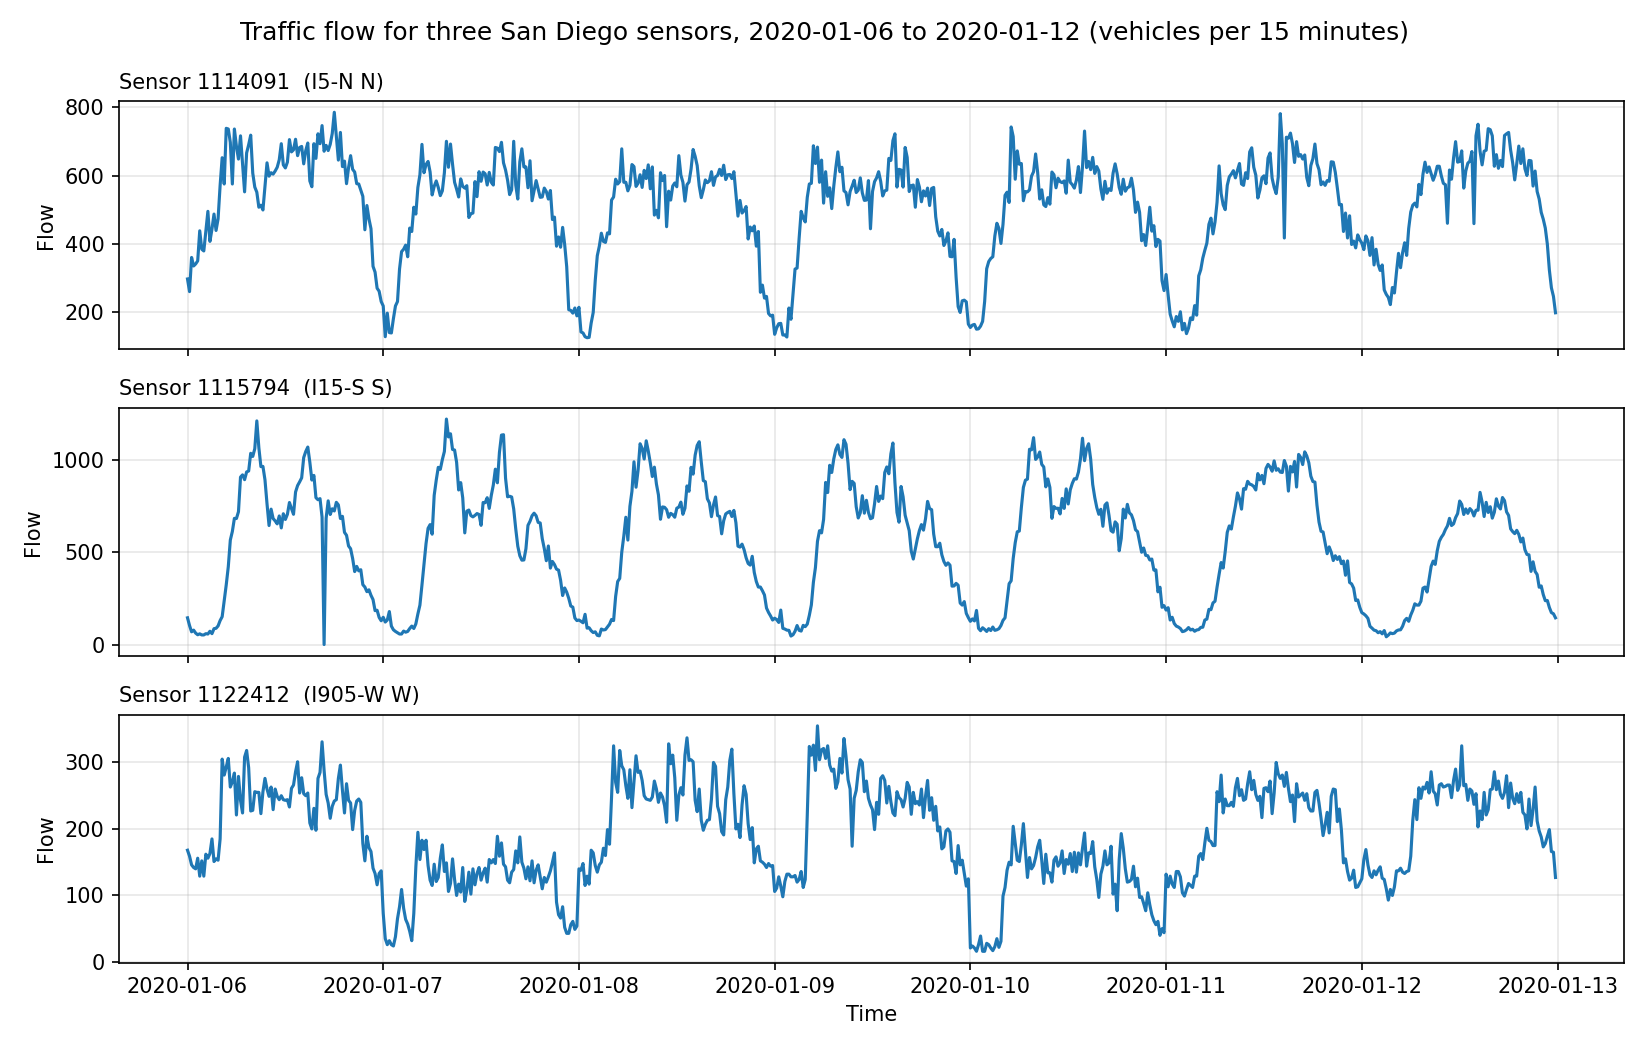

Displaying: q3b_adjacency_heatmap.png


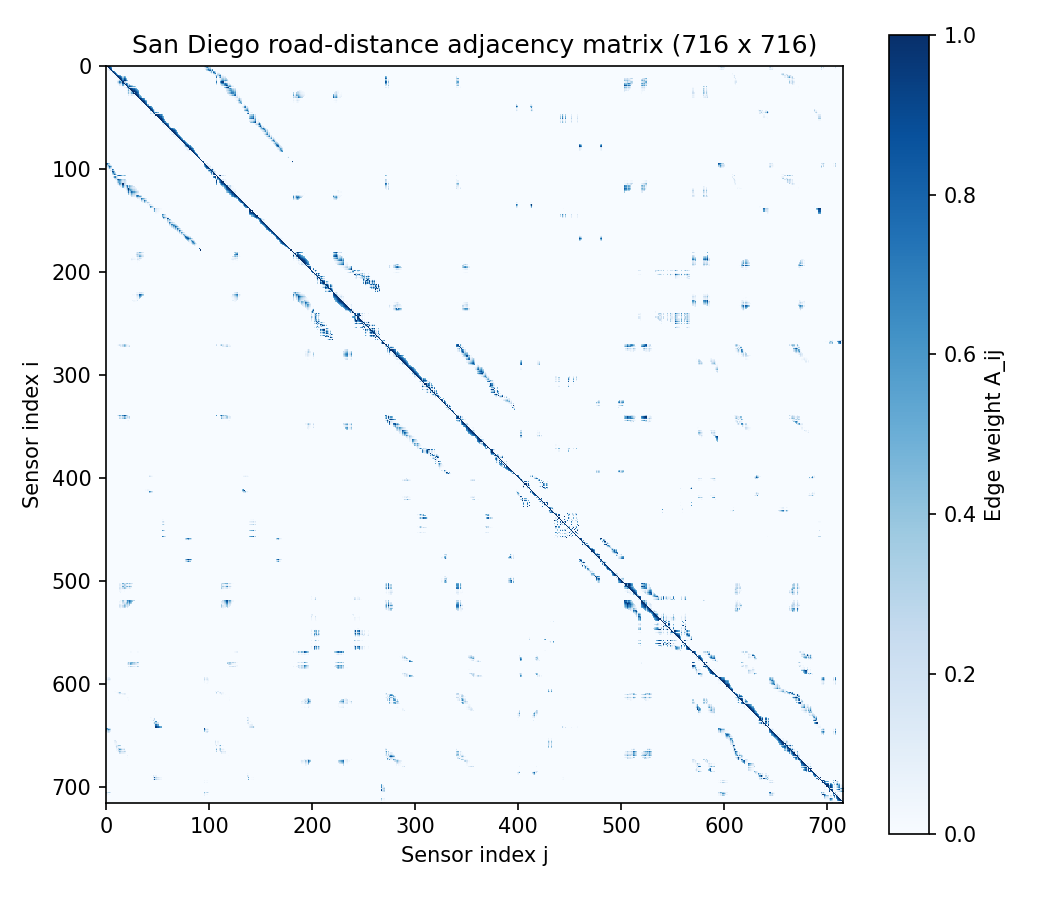

Displaying: q3b_neighbour_distribution.png


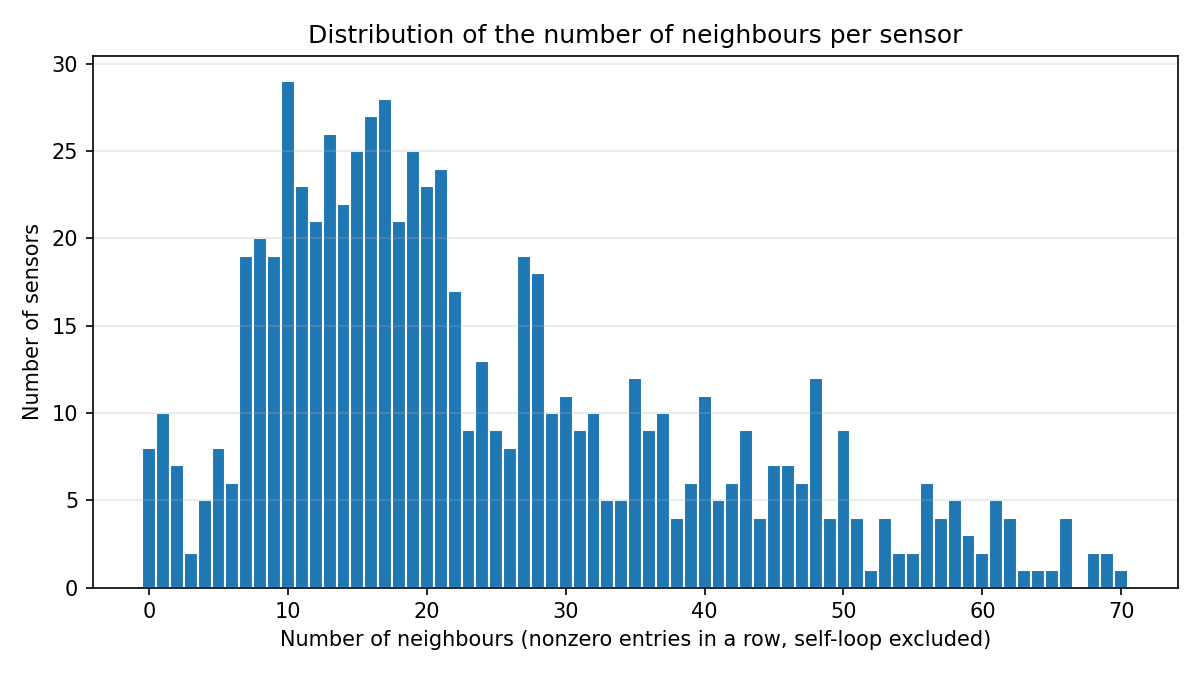

In [9]:
import os
from IPython.display import Image, display
image_files = [
    "q3a_three_sensors_week.png",
    "q3b_adjacency_heatmap.png",
    "q3b_neighbour_distribution.png"
]

for img_name in image_files:
    img_path = os.path.join(OUT_DIR, img_name)
    if os.path.exists(img_path):
        print(f"{img_name}")
        display(Image(filename=img_path))
    else:
        print(f"cant find: {img_path}")